# Implementing and testing KV cache

In [1]:
%load_ext autoreload
%autoreload 2

save reference outputs

In [ ]:
import os, torch
from gpt.generate import load_model

model, cfg = load_model("../runs/pretrain_v2/best.pt")
print(type(model).__name__, cfg.n_layer, cfg.d_model, cfg.context_len, hasattr(model, "make_cache"))
if os.path.exists("../ref_logits.pt"):
    print("reference already saved; not overwriting")
else:
    torch.manual_seed(0)
    idx = torch.randint(0, cfg.vocab_size, (2, 64))
    with torch.no_grad():
        ref, _ = model(idx)
    torch.save({"idx": idx, "logits": ref}, "../ref_logits.pt")

In [3]:
import pandas as pd
from gpt.generate import load_model

model, cfg = load_model("../runs/pretrain_v2/best.pt")
L, d, V, T = cfg.n_layer, cfg.d_model, cfg.vocab_size, cfg.context_len
n_params = sum(p.numel() for p in model.parameters())
weights_mb = n_params * 4 / 1e6

def kv_bytes(B, T, nbytes):                    # keys + values, all layers
    return 2 * L * d * T * B * nbytes

rows = [{"B": B, "dtype": n, "cache MB": round(kv_bytes(B, T, nb) / 1e6, 1),
         "cache / weights": round(kv_bytes(B, T, nb) / 1e6 / weights_mb, 2)}
        for B in (1, 8, 32, 64, 256) for n, nb in (("fp32", 4), ("fp16", 2))]
print(f"params {n_params/1e6:.1f}M | weights fp32 {weights_mb:.1f} MB | KV per token {kv_bytes(1, 1, 4)/1e3:.1f} KB (fp32)")
print(pd.DataFrame(rows).to_string(index=False))

dense = 2 * (12 * L * d * d + V * d)           # matmul FLOPs per token: attention projections + MLP + tied head
attn = lambda t: 4 * L * d * t                 # QK^T and AV against t cached positions
print(f"\ndense FLOPs/token: {dense/1e6:.1f}M")
for t in (16, 64, 128, 256):
    print(f"t={t:3d}: attention {attn(t)/1e6:5.2f}M ({attn(t)/dense:5.1%} of dense) | "
          f"no-cache step ~{t * dense / 1e6:6.0f}M FLOPs vs cached {(dense + attn(t)) / 1e6:5.1f}M")

params 12.2M | weights fp32 48.8 MB | KV per token 18.4 KB (fp32)
  B dtype  cache MB  cache / weights
  1  fp32       4.7             0.10
  1  fp16       2.4             0.05
  8  fp32      37.7             0.77
  8  fp16      18.9             0.39
 32  fp32     151.0             3.10
 32  fp16      75.5             1.55
 64  fp32     302.0             6.19
 64  fp16     151.0             3.10
256  fp32    1208.0            24.76
256  fp16     604.0            12.38

dense FLOPs/token: 24.4M
t= 16: attention  0.15M ( 0.6% of dense) | no-cache step ~   390M FLOPs vs cached  24.5M
t= 64: attention  0.59M ( 2.4% of dense) | no-cache step ~  1560M FLOPs vs cached  25.0M
t=128: attention  1.18M ( 4.8% of dense) | no-cache step ~  3121M FLOPs vs cached  25.6M
t=256: attention  2.36M ( 9.7% of dense) | no-cache step ~  6241M FLOPs vs cached  26.7M


## Cache created

In [4]:
model, cfg = load_model("../runs/pretrain_v2/best.pt")
cache = model.make_cache(B=2)
assert len(cache) == cfg.n_layer
k, v = cache[0]
assert k.shape == v.shape == (2, cfg.n_head, cfg.context_len, cfg.d_model // cfg.n_head)
assert k.data_ptr() != v.data_ptr() and cache[0][0].data_ptr() != cache[1][0].data_ptr()   # no shared storage
assert k.device == model.tok_emb.weight.device and k.dtype == model.tok_emb.weight.dtype

total = sum(t.numel() * t.element_size() for kv in cache for t in kv)
print(total / 1e6, "MB")        # compare with your analytic cell: 2 * L * d * T * B * 4 bytes = 9.4 MB for B=2

9.437184 MB


## Test

In [3]:
%load_ext autoreload
%autoreload 2
import os, torch
from gpt.generate import load_model

model, cfg = load_model("../runs/pretrain_v2/best.pt")
model.eval()

# 1) regression: the plain path must still match the logits saved before the edits
if os.path.exists("../ref_logits.pt"):
    ref = torch.load("../ref_logits.pt")
    with torch.no_grad():
        new, _ = model(ref["idx"])
    print("regression max diff:", (new - ref["logits"]).abs().max().item())       # expect ~0 (below 1e-6)
else:
    print("no ../ref_logits.pt: skipping the regression check")


@torch.no_grad()
def run_cached(idx, t0, cache):
    # prefill the first t0 tokens, then decode one token at a time; returns logits for every position
    out, _ = model(idx[:, :t0], start_pos=0, cache=cache)
    steps = [out]
    for t in range(t0, idx.shape[1]):
        out, _ = model(idx[:, t:t + 1], start_pos=t, cache=cache)
        steps.append(out)
    return torch.cat(steps, dim=1)


@torch.no_grad()
def check(B, T, prefills, seed=0):
    g = torch.Generator().manual_seed(seed)
    idx = torch.randint(0, cfg.vocab_size, (B, T), generator=g)
    full, _ = model(idx)                                                           # plain path, (B, T, V)
    for t0 in prefills:
        cached = run_cached(idx, t0, model.make_cache(B))
        assert cached.shape == full.shape
        d = (cached - full).abs()
        agree = (cached.argmax(-1) == full.argmax(-1)).float().mean().item()
        print(f"B={B} T={T} prefill={t0:3d} | max diff {d.max().item():.2e} | "
              f"worst position {d.amax(dim=(0, 2)).argmax().item():3d} | argmax agreement {agree:.1%}")


# 2) equivalence: cached logits vs full recompute, at several prefill lengths and batch sizes
check(B=1, T=64, prefills=(1, 10, 64))
check(B=3, T=64, prefills=(1, 16))

# 3) reusing one cache for a second, shorter sequence (stale entries from the first must never be read)
with torch.no_grad():
    cache = model.make_cache(1)
    g = torch.Generator().manual_seed(1)
    long_seq = torch.randint(0, cfg.vocab_size, (1, 100), generator=g)
    short_seq = torch.randint(0, cfg.vocab_size, (1, 30), generator=g)
    run_cached(long_seq, 10, cache)
    again = run_cached(short_seq, 10, cache)
    ref_short, _ = model(short_seq)
    print("cache reuse max diff:", (again - ref_short).abs().max().item())

# 4) the guards must fire
for name, fn in {
    "multi-token input with a non-empty cache": lambda: model(torch.zeros(1, 2, dtype=torch.long), start_pos=5, cache=model.make_cache(1)),
    "writing past the end of the cache": lambda: model(torch.zeros(1, 1, dtype=torch.long), start_pos=cfg.context_len, cache=model.make_cache(1)),
}.items():
    try:
        with torch.no_grad():
            fn()
        print("MISSING GUARD:", name)
    except AssertionError as e:
        print("guard OK:", name)

# 5) memory: measured buffer size against the analytic prediction (2 * L * d * T * B * 4 bytes)
cache = model.make_cache(2)
measured = sum(t.numel() * t.element_size() for kv in cache for t in kv)
print(f"cache B=2: {measured / 1e6:.2f} MB (predicted {2 * cfg.n_layer * cfg.d_model * cfg.context_len * 2 * 4 / 1e6:.2f} MB)")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
regression max diff: 0.0
B=1 T=64 prefill=  1 | max diff 1.00e-05 | worst position  51 | argmax agreement 100.0%
B=1 T=64 prefill= 10 | max diff 1.12e-05 | worst position  41 | argmax agreement 100.0%
B=1 T=64 prefill= 64 | max diff 0.00e+00 | worst position   0 | argmax agreement 100.0%
B=3 T=64 prefill=  1 | max diff 1.14e-05 | worst position   5 | argmax agreement 100.0%
B=3 T=64 prefill= 16 | max diff 1.05e-05 | worst position  54 | argmax agreement 100.0%
cache reuse max diff: 7.62939453125e-06
guard OK: multi-token input with a non-empty cache
guard OK: writing past the end of the cache
cache B=2: 9.44 MB (predicted 9.44 MB)


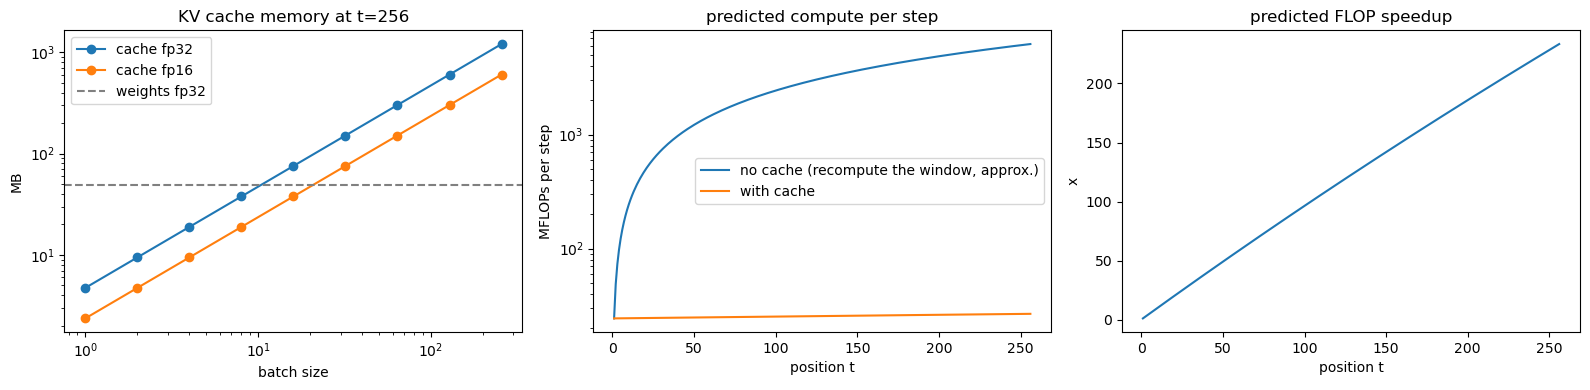

In [4]:
import numpy as np, matplotlib.pyplot as plt

L, d, V, T = cfg.n_layer, cfg.d_model, cfg.vocab_size, cfg.context_len
weights_mb = sum(p.numel() for p in model.parameters()) * 4 / 1e6
kv_mb = lambda B, t, nbytes=4: 2 * L * d * t * B * nbytes / 1e6

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

Bs = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256])                   # (a) cache memory vs batch size, at full context
ax[0].plot(Bs, kv_mb(Bs, T, 4), marker="o", label="cache fp32")
ax[0].plot(Bs, kv_mb(Bs, T, 2), marker="o", label="cache fp16")
ax[0].axhline(weights_mb, color="gray", ls="--", label="weights fp32")
ax[0].set(xscale="log", yscale="log", xlabel="batch size", ylabel="MB", title=f"KV cache memory at t={T}")
ax[0].legend()

t = np.arange(1, T + 1)                                              # (b) FLOPs per generated token vs position
dense = 2 * (12 * L * d * d + V * d)                                 # projections + MLP + tied head
attn = 4 * L * d * t                                                 # QK^T and AV against t cached positions
ax[1].plot(t, t * dense / 1e6, label="no cache (recompute the window, approx.)")
ax[1].plot(t, (dense + attn) / 1e6, label="with cache")
ax[1].set(yscale="log", xlabel="position t", ylabel="MFLOPs per step", title="predicted compute per step")
ax[1].legend()

ax[2].plot(t, t * dense / (dense + attn))                            # (c) predicted FLOP speedup
ax[2].set(xlabel="position t", ylabel="x", title="predicted FLOP speedup")
plt.tight_layout(); plt.show()

threads: 6


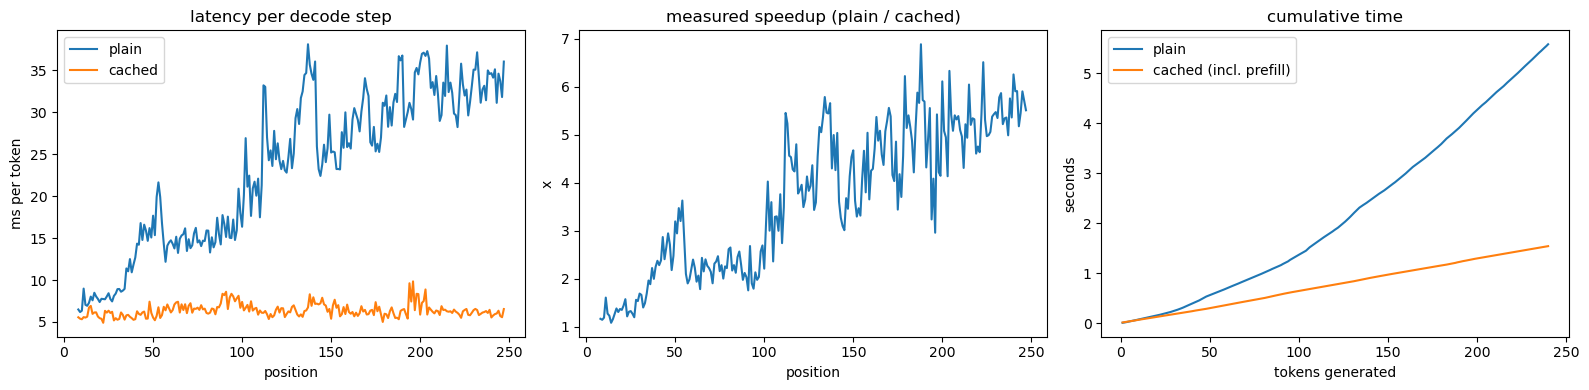

prefill (8 tokens): 7.8 ms


In [5]:
import time, torch

print("threads:", torch.get_num_threads())
sync = torch.cuda.synchronize if torch.cuda.is_available() else (lambda: None)


@torch.no_grad()
def time_plain(prompt_len, n_new, B=1, seed=0):
    idx = torch.randint(0, V, (B, prompt_len), generator=torch.Generator().manual_seed(seed))
    lat = []
    for _ in range(n_new):
        sync(); t0 = time.perf_counter()
        logits, _ = model(idx[:, -T:])                              # the whole window, every step
        sync(); lat.append(time.perf_counter() - t0)
        idx = torch.cat([idx, logits[:, -1].argmax(-1, keepdim=True)], 1)
    return np.array(lat)


@torch.no_grad()
def time_cached(prompt_len, n_new, B=1, seed=0):
    idx = torch.randint(0, V, (B, prompt_len), generator=torch.Generator().manual_seed(seed))
    cache = model.make_cache(B)
    sync(); t0 = time.perf_counter()
    logits, _ = model(idx, start_pos=0, cache=cache)                # prefill
    sync(); prefill = time.perf_counter() - t0
    lat, pos = [], prompt_len
    for _ in range(n_new):
        nxt = logits[:, -1].argmax(-1, keepdim=True)
        sync(); t0 = time.perf_counter()
        logits, _ = model(nxt, start_pos=pos, cache=cache)          # one token per step
        sync(); lat.append(time.perf_counter() - t0)
        pos += 1
    return prefill, np.array(lat)


P, N, REPS = 8, T - 8 - 8, 3                                        # prompt 8, generate 240: stays inside the 256 window
time_plain(P, 5); time_cached(P, 5)                                 # warm-up
plain = np.median([time_plain(P, N) for _ in range(REPS)], axis=0)
runs = [time_cached(P, N) for _ in range(REPS)]
prefill = np.median([r[0] for r in runs])
cached = np.median([r[1] for r in runs], axis=0)
pos = np.arange(P, P + N)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(pos, plain * 1e3, label="plain"); ax[0].plot(pos, cached * 1e3, label="cached")
ax[0].set(xlabel="position", ylabel="ms per token", title="latency per decode step"); ax[0].legend()

ax[1].plot(pos, plain / cached)
ax[1].set(xlabel="position", ylabel="x", title="measured speedup (plain / cached)")

ax[2].plot(np.arange(1, N + 1), np.cumsum(plain), label="plain")
ax[2].plot(np.arange(1, N + 1), prefill + np.cumsum(cached), label="cached (incl. prefill)")
ax[2].set(xlabel="tokens generated", ylabel="seconds", title="cumulative time"); ax[2].legend()
plt.tight_layout(); plt.show()
print(f"prefill ({P} tokens): {prefill * 1e3:.1f} ms")

B=  1:      133 tokens/s
B=  4:      601 tokens/s
B= 16:     1638 tokens/s
B= 64:     3853 tokens/s


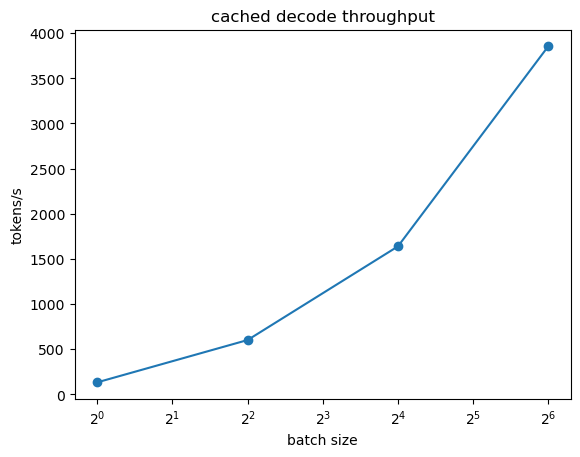

In [6]:
rows = []
for B in (1, 4, 16, 64):
    _, lat = time_cached(16, 100, B=B)
    rows.append((B, B / np.median(lat)))
    print(f"B={B:3d}: {rows[-1][1]:8.0f} tokens/s")
Bs_, tps = zip(*rows)
plt.plot(Bs_, tps, marker="o"); plt.xscale("log", base=2)
plt.xlabel("batch size"); plt.ylabel("tokens/s"); plt.title("cached decode throughput"); plt.show()

B=   1 |    8.15 ms/step |       123 tokens/s | scaling efficiency  1.00
B=   2 |    6.81 ms/step |       294 tokens/s | scaling efficiency  1.20
B=   4 |    7.35 ms/step |       544 tokens/s | scaling efficiency  1.11
B=   8 |    7.46 ms/step |      1073 tokens/s | scaling efficiency  1.09
B=  16 |    8.10 ms/step |      1975 tokens/s | scaling efficiency  1.01
B=  32 |   10.92 ms/step |      2930 tokens/s | scaling efficiency  0.75
B=  64 |   17.53 ms/step |      3651 tokens/s | scaling efficiency  0.46
B= 128 |   30.12 ms/step |      4250 tokens/s | scaling efficiency  0.27


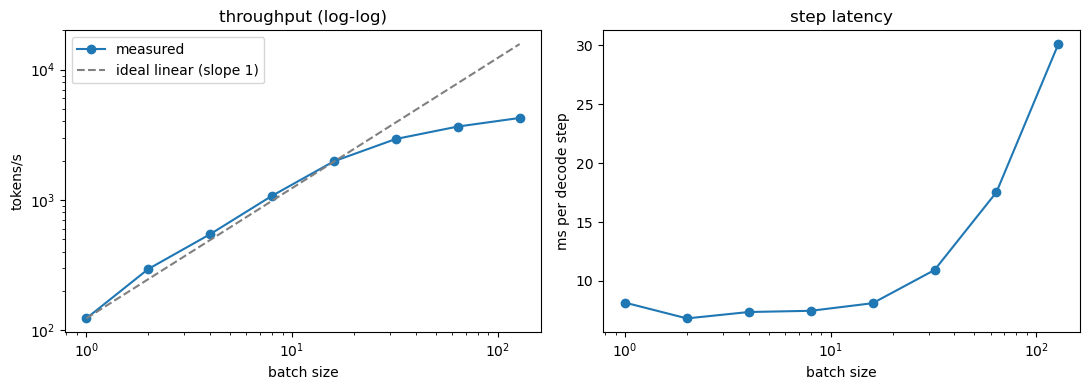

log-log slope over the first 4 points: 1.03


In [7]:
rows = []
for B in (1, 2, 4, 8, 16, 32, 64, 128):
    time_cached(16, 10, B=B)                                                  # warm-up for this batch size
    lats = [np.median(time_cached(16, 60, B=B)[1][5:]) for _ in range(3)]     # skip the first 5 noisy steps
    rows.append((B, np.median(lats)))
Bs_ = np.array([r[0] for r in rows]); lat = np.array([r[1] for r in rows])
tps = Bs_ / lat
for B, l, t in zip(Bs_, lat, tps):
    print(f"B={B:4d} | {l * 1e3:7.2f} ms/step | {t:9.0f} tokens/s | scaling efficiency {lat[0] / l:5.2f}")   # 1.0 = ideal; >1 = superlinear

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(Bs_, tps, marker="o", label="measured")
ax[0].loglog(Bs_, tps[0] * Bs_, "--", color="gray", label="ideal linear (slope 1)")
ax[0].set(xlabel="batch size", ylabel="tokens/s", title="throughput (log-log)"); ax[0].legend()
ax[1].semilogx(Bs_, lat * 1e3, marker="o")
ax[1].set(xlabel="batch size", ylabel="ms per decode step", title="step latency")
plt.tight_layout(); plt.show()
print("log-log slope over the first 4 points:", np.polyfit(np.log(Bs_[:4]), np.log(tps[:4]), 1)[0].round(2))